<a href="https://colab.research.google.com/github/edwardoughton/spatial_computing/blob/main/08_01_Scripting_Spatial_Processing_via_GeoPandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌍 🗺️ **Week 8: Spatial processing with GeoPandas — Part 1** 🌍 🗺️

Today we will get stuck into working with real data in Pandas and GeoPandas.

For example, we will download spatial data from a server and build a processing workflow.

We will cover reading and checking data, projecting it, calculating area, filtering rows, mapping results, exporting layers, creating boundaries and centroids, and converting between GeoDataFrames and Python records.

**Question:** How do the areas of Virginia counties and independent cities compare?

By the end, submit a map, a summary CSV, a spatial output, and three sentences describing a finding and a limitation. These are administrative polygons, not measurements of population or service access.

Run examples in order. Task cells are for your own code. If GeoPandas is unavailable, run `%pip install geopandas matplotlib` in a separate cell and retry.


## 🧭 Recap on `GeoPandas`

`GeoPandas` is a very popular spatial data processing package based on the popular `Pandas` library.

Essentially, `GeoPandas` provides us with a range of useful spatial functions enabling us to swiftly analyze and manipulate spatial data via a dataframe structure.

* The key data structure within `GeoPandas` is a `GeoDataFrame` which essentially stores our spatial data in a `Pandas` dataframe, only with an additional geometry column containing a `Shapely` object.
* A range of spatial operations are thus available to us for use via our `GeoDataFrame` structure, including overlaying geometries, spatial joins, and geometry buffering. Via these tools we can quantify relationships between different geospatial entities, using these results for a wide range of applications (e.g., writing scientific papers, decision-support modeling etc.).
* We can easily handle importing and exporting spatial data thanks to the range of functionalities `GeoPandas` provides. This includes importing/exporting geospatial data via Shapefile, GeoJSON, GeoPackage etc. This reduces the number of lines of additional code we need to allocate to these more basic/vanilla tasks.
* Other libraries may have useful functions we want to use, and `GeoPandas` provides us with the ability to seamlessly integrate with other popular geospatial libraries. For example, we can utilize geometric operations available within Shapely and readily apply them to the geometries within our dataframe.
* Finally, `GeoPandas` does provide different plotting capabilities for visualizing geospatial data directly from a `GeoDataFrame`. Just be aware this will require Matplotlib for more basic plotting functions, or utilizing more niche libraries for more advanced mapping.

Let us get into exploring more of these capabilities using actual coding examples.



## 🧩 `GeoPandas` types and subclasses

`GeoPandas` implements `GeoSeries` and `GeoDataFrame` structures, which are both subclasses of `pandas.Series` and `pandas.DataFrame`. Geometries are handled in the `geopandas.GeoSeries`, via shapely.

Therefore, your `GeoDataFrame` is a combination of `pandas.Series`, with traditional data (numerical, boolean, text etc.), and `geopandas.GeoSeries`, with geometries (points, polygons etc.).


## 🌐 📥 Download spatial data from a server

Use the same Virginia dataset as Week 6. The HTTPS URL points to a fixed course-data version. A raw-data URL returns a file rather than a GitHub webpage.

Here we explicitly download and save the ZIP before reading it. This gives us a reusable local copy and separates acquisition from processing. The archive contains the shapefile and its companion `.dbf`, `.shx`, `.prj`, and `.cpg` files.

An internet connection is required for this cell. Keep the source URL with your results. See [GeoPandas reading and writing files](https://geopandas.org/en/stable/docs/user_guide/io.html).


In [ ]:
# simple way to load in our data
from urllib.request import urlretrieve

url = "https://raw.githubusercontent.com/edwardoughton/spatial_computing/main/data/virginia.zip"
urlretrieve(url, "virginia.zip")

In [37]:
# This approach puts the data in a folder called "data"
from pathlib import Path
from urllib.request import urlretrieve

data_url = 'https://raw.githubusercontent.com/edwardoughton/spatial_computing/510dcb3b7d6954999434df162b077dabe2a98891/data/virginia.zip'
data_dir = Path('data')
data_dir.mkdir(exist_ok=True)
data_path = data_dir / 'virginia.zip'
urlretrieve(data_url)
print(f'Downloaded {data_path.stat().st_size:,} bytes from {data_url}')


Downloaded 515,560 bytes from https://raw.githubusercontent.com/edwardoughton/spatial_computing/510dcb3b7d6954999434df162b077dabe2a98891/data/virginia.zip


Read the saved ZIP with `gpd.read_file()`. GeoPandas reads the source CRS from the dataset; do not override it on import. Inspect the returned records before doing calculations.


In [38]:
%pip install geopandas matplotlib

In [39]:
import geopandas as gpd
import matplotlib.pyplot as plt

source_gdf = gpd.read_file(data_path)
print('Features:', len(source_gdf), '| CRS:', source_gdf.crs)
print(source_gdf.geom_type.value_counts())
print('Missing geometries:', source_gdf.geometry.isna().sum())
print('Empty geometries:', source_gdf.geometry.is_empty.sum())
print('Invalid geometries:', (~source_gdf.geometry.is_valid).sum())
source_gdf.head(3)


Features: 133 | CRS: EPSG:4326
Polygon         111
MultiPolygon     22
Name: count, dtype: int64
Missing geometries: 0
Empty geometries: 0
Invalid geometries: 0


,GID_0,NAME_0,GID_1,NAME_1,NL_NAME_1,GID_2,NAME_2,VARNAME_2,NL_NAME_2,TYPE_2,ENGTYPE_2,CC_2,HASC_2,geometry
0,USA,United States,USA.47_1,Virginia,None,USA.47.1_1,Accomack,None,None,County,County,None,US.VA.AC,"MULTIPOLYGON (((-75.39167 37.87611, -75.39111 ..."
1,USA,United States,USA.47_1,Virginia,None,USA.47.2_1,Albemarle,None,None,County,County,None,US.VA.AB,"POLYGON ((-78.30585 38.00703, -78.48742 37.801..."
2,USA,United States,USA.47_1,Virginia,None,USA.47.3_1,Alexandria,None,None,Independent City,Independent City,None,US.VA.AX,"POLYGON ((-77.04556 38.83995, -77.04572 38.839..."


You might find it easier to subset your `GeoDataframe`, which you can easily do the same way that we utilized in `Pandas`.


In [40]:
gdf = source_gdf[['GID_2', 'geometry', 'NAME_1', 'NAME_2', 'TYPE_2']].copy()
gdf.head(3)


,GID_2,geometry,NAME_1,NAME_2,TYPE_2
0,USA.47.1_1,"MULTIPOLYGON (((-75.39167 37.87611, -75.39111 ...",Virginia,Accomack,County
1,USA.47.2_1,"POLYGON ((-78.30585 38.00703, -78.48742 37.801...",Virginia,Albemarle,County
2,USA.47.3_1,"POLYGON ((-77.04556 38.83995, -77.04572 38.839...",Virginia,Alexandria,Independent City


## 🎯 🔎 Task: inspect before processing

Print the column names, administrative types, and number of unique `GID_2` values. Does each row have a unique identifier? Compare the row count with Week 6. What can you learn from the geometry checks, and what do they leave unknown?


## 🧭 🌍 Managing coordinate reference systems

The `.crs` property reports the current CRS. Longitude and latitude are measured in degrees. Use a suitable projected CRS before calculating area or centroids.


In [41]:
# Example: Checking the crs of our dataframe
gdf.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

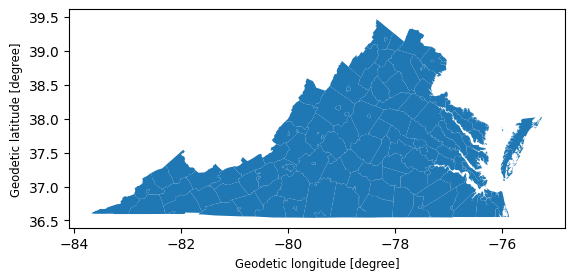

In [42]:
# Example: Plotting the data to view crs units via `.plot()`
gdf.plot()

### 🗺️ Add a basemap

Our first plot shows the shapes. A **basemap** adds familiar context, such as place names, roads, and rivers, behind them.

Run the installation cell once, then draw the map below. `contextily` downloads background map tiles over the internet; no API key is needed for this example.

We use transparent polygon interiors so the background remains visible. `ax` is the map's plotting area. Passing `crs=gdf.crs` tells Contextily how to align the basemap with our shapes. We will transform our data for area calculations in the next section.

See the [Contextily basemap documentation](https://contextily.readthedocs.io/en/latest/reference.html#contextily.add_basemap).


In [43]:
%pip install -q contextily


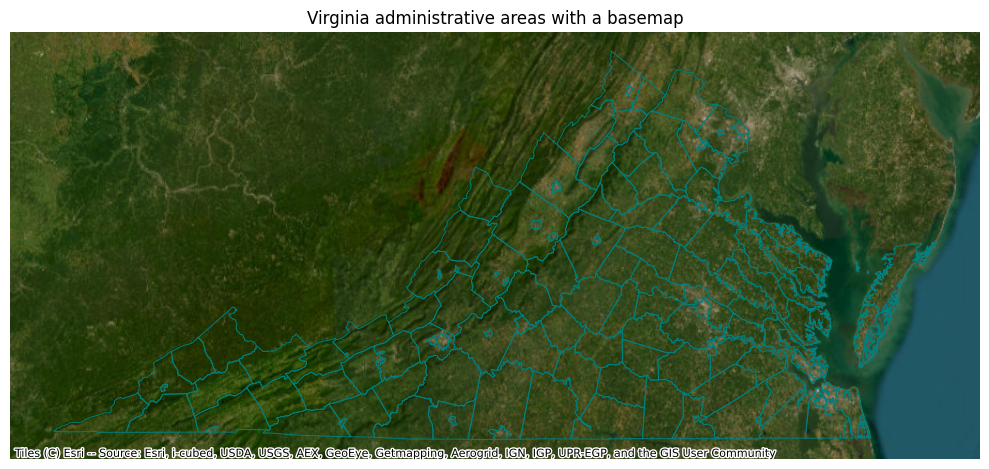

In [44]:
import contextily as ctx

ax = gdf.plot(facecolor='none', edgecolor='teal', linewidth=0.7, figsize=(10, 6))
ctx.add_basemap(ax, crs=gdf.crs, source=ctx.providers.Esri.WorldImagery, zoom=7)
ax.set_title('Virginia administrative areas with a basemap')
ax.set_axis_off()
plt.tight_layout()
plt.show()


**Try it:** change `edgecolor='teal'` to another color and rerun the map. What is easier to recognize with the basemap?

Keep the map-provider attribution displayed on the map. If the tile service is unavailable, continue with the plain `gdf.plot()` above; the analysis does not depend on the background map.


Use `.to_crs()` to transform coordinates. Here we use EPSG:3968 (NAD83 / Virginia Lambert), a projected CRS designed for Virginia with meter units. Web Mercator (EPSG:3857) distorts area and is unsuitable for these comparisons.

`.set_crs()` assigns a known CRS label; it does not transform coordinates. Never guess the source CRS.


In [45]:
gdf = gdf.to_crs('EPSG:3968')
gdf.head(3)


,GID_2,geometry,NAME_1,NAME_2,TYPE_2
0,USA.47.1_1,"MULTIPOLYGON (((361254.367 216238.5, 361303.30...",Virginia,Accomack,County
1,USA.47.2_1,"POLYGON ((104848.569 223423.067, 89157.028 200...",Virginia,Albemarle,County
2,USA.47.3_1,"POLYGON ((213033.552 318009.489, 213020.401 31...",Virginia,Alexandria,Independent City


In [46]:
# Example: Check changed crs
gdf.crs

<Projected CRS: EPSG:3968>
Name: NAD83 / Virginia Lambert
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: United States (USA) - Virginia.
- bounds: (-83.68, 36.54, -75.31, 39.46)
Coordinate Operation:
- name: Virginia Lambert Conic Conformal
- method: Lambert Conic Conformal (2SP)
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

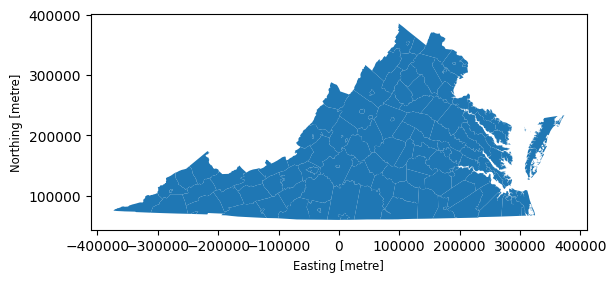

In [47]:
# Example: Plotting the data to view crs units via `.plot()`
gdf.plot()

## ➕ Creating a new column

Next, we can consider how we would create a new column in a `GeoPandas` `GeoDataFrame`.

For example, we could just create a single column with a pre-defined value for all columns (the most straight-forward example):

In [48]:
# Example: Adding a new column
gdf['new_column'] = 'I_am_a_string'
gdf['new_column2'] = 53.5
gdf['new_column3'] = 0
gdf['new_column4'] = "(2.334, 4.653)"
gdf.head(3)

,GID_2,geometry,NAME_1,NAME_2,TYPE_2,new_column,new_column2,new_column3,new_column4
0,USA.47.1_1,"MULTIPOLYGON (((361254.367 216238.5, 361303.30...",Virginia,Accomack,County,I_am_a_string,53.5,0,"(2.334, 4.653)"
1,USA.47.2_1,"POLYGON ((104848.569 223423.067, 89157.028 200...",Virginia,Albemarle,County,I_am_a_string,53.5,0,"(2.334, 4.653)"
2,USA.47.3_1,"POLYGON ((213033.552 318009.489, 213020.401 31...",Virginia,Alexandria,Independent City,I_am_a_string,53.5,0,"(2.334, 4.653)"


Calculate each polygon's area with `.geometry.area`. The projected coordinates have meter units, so the resulting area is in square meters. Reprojection changes geometry but does not recalculate existing numeric area columns.


In [49]:
# Example: Finding the area of our polygons in square meters
gdf['area_m2'] = gdf['geometry'].area
gdf.head(3)

,GID_2,geometry,NAME_1,NAME_2,TYPE_2,new_column,new_column2,new_column3,new_column4,area_m2
0,USA.47.1_1,"MULTIPOLYGON (((361254.367 216238.5, 361303.30...",Virginia,Accomack,County,I_am_a_string,53.5,0,"(2.334, 4.653)",1.236714e+09
1,USA.47.2_1,"POLYGON ((104848.569 223423.067, 89157.028 200...",Virginia,Albemarle,County,I_am_a_string,53.5,0,"(2.334, 4.653)",1.873436e+09
2,USA.47.3_1,"POLYGON ((213033.552 318009.489, 213020.401 31...",Virginia,Alexandria,Independent City,I_am_a_string,53.5,0,"(2.334, 4.653)",4.055737e+07


If we want to then create a new column with the area in square kilometers, we would divide by 1x10^6.

In [55]:
# Example: Finding the area of our polygons in square kilometers
gdf['area_km2'] = gdf['area_m2'] / 1e6
gdf.head(3)

,GID_2,geometry,NAME_1,NAME_2,TYPE_2,new_column,new_column2,new_column3,new_column4,area_m2,area_km2
0,USA.47.1_1,"MULTIPOLYGON (((361254.367 216238.5, 361303.30...",Virginia,Accomack,County,I_am_a_string,53.5,0,"(2.334, 4.653)",1.236714e+09,1236.714082
1,USA.47.2_1,"POLYGON ((104848.569 223423.067, 89157.028 200...",Virginia,Albemarle,County,I_am_a_string,53.5,0,"(2.334, 4.653)",1.873436e+09,1873.435909
2,USA.47.3_1,"POLYGON ((213033.552 318009.489, 213020.401 31...",Virginia,Alexandria,Independent City,I_am_a_string,53.5,0,"(2.334, 4.653)",4.055737e+07,40.557368


## 🗺️ 🎨 Plotting

`GeoPandas` provides an easy plotting interface via the `GeoDataFrame.plot()` function.

To colorcode the map, we can pass the column of interest, like so:

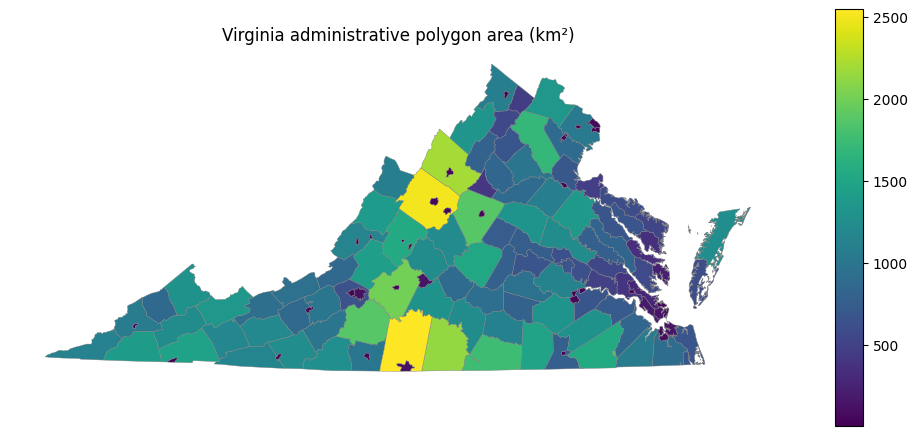

In [51]:
ax = gdf.plot(column='area_km2', legend=True, edgecolor='gray', linewidth=0.3, figsize=(10, 6))
ax.set_title('Virginia administrative polygon area (km²)')
ax.set_axis_off()
plt.tight_layout()
plt.show()


## 🛠️ Manipulating column data




Use an actual missing numeric value (`float('nan')`), rather than the text `'NaN'`. Work on a copy to preserve our calculated results.


In [52]:
example_gdf = gdf.copy()
example_gdf['area_km2'] = float('nan')
example_gdf.head(3)


,GID_2,geometry,NAME_1,NAME_2,TYPE_2,new_column,new_column2,new_column3,new_column4,area_m2,area_km2
0,USA.47.1_1,"MULTIPOLYGON (((361254.367 216238.5, 361303.30...",Virginia,Accomack,County,I_am_a_string,53.5,0,"(2.334, 4.653)",1.236714e+09,NaN
1,USA.47.2_1,"POLYGON ((104848.569 223423.067, 89157.028 200...",Virginia,Albemarle,County,I_am_a_string,53.5,0,"(2.334, 4.653)",1.873436e+09,NaN
2,USA.47.3_1,"POLYGON ((213033.552 318009.489, 213020.401 31...",Virginia,Alexandria,Independent City,I_am_a_string,53.5,0,"(2.334, 4.653)",4.055737e+07,NaN


Fill the example column by calculating area again. The main `gdf` remains available for filtering and analysis.


In [53]:
example_gdf['area_km2'] = example_gdf.geometry.area / 1e6
example_gdf.head(3)


,GID_2,geometry,NAME_1,NAME_2,TYPE_2,new_column,new_column2,new_column3,new_column4,area_m2,area_km2
0,USA.47.1_1,"MULTIPOLYGON (((361254.367 216238.5, 361303.30...",Virginia,Accomack,County,I_am_a_string,53.5,0,"(2.334, 4.653)",1.236714e+09,1236.714082
1,USA.47.2_1,"POLYGON ((104848.569 223423.067, 89157.028 200...",Virginia,Albemarle,County,I_am_a_string,53.5,0,"(2.334, 4.653)",1.873436e+09,1873.435909
2,USA.47.3_1,"POLYGON ((213033.552 318009.489, 213020.401 31...",Virginia,Alexandria,Independent City,I_am_a_string,53.5,0,"(2.334, 4.653)",4.055737e+07,40.557368


# 🔎 Subsetting rows


We can subset the rows of the dataframe in a variety of ways. You need to familiarize yourself with how to subset based on the different options available.

For example, what about if we wanted to subset those with an area below the mean?



In [56]:
# Example: Subsetting rows below the mean
mean_area_km2 = gdf['area_km2'].mean()
print("The mean area of Virginia GID_2 regions is {} km2".format(mean_area_km2))

print("Currently we have {} areas (e.g., {} rows)".format(len(gdf), len(gdf)))
subset = gdf[gdf['area_km2'] < mean_area_km2]
print("Now we have {} areas (e.g., {} rows)".format(len(subset), len(subset)))
subset.head(3)

The mean area of Virginia GID_2 regions is 779.9084710210763 km2
Currently we have 133 areas (e.g., 133 rows)
Now we have 66 areas (e.g., 66 rows)


,GID_2,geometry,NAME_1,NAME_2,TYPE_2,new_column,new_column2,new_column3,new_column4,area_m2,area_km2
2,USA.47.3_1,"POLYGON ((213033.552 318009.489, 213020.401 31...",Virginia,Alexandria,Independent City,I_am_a_string,53.5,0,"(2.334, 4.653)",4.055737e+07,40.557368
7,USA.47.8_1,"POLYGON ((207400.13 318275.817, 203913.023 321...",Virginia,Arlington,County,I_am_a_string,53.5,0,"(2.334, 4.653)",6.896114e+07,68.961144
11,USA.47.12_1,"POLYGON ((1355.207 149702.324, 636.977 146281....",Virginia,Bedford City,City,I_am_a_string,53.5,0,"(2.334, 4.653)",2.221135e+07,22.211349


The way to understand this code:

`subset = gdf[gdf['area_km2'] < mean_area_km2]`

Is by recognizing:

* The first part to the left of the equals allocates the results to a new df called `subset`.
* The inner layer of the square parentheses evaluates whether the `area_km2` value is below the `mean_area_km2` (leading to a value for each row of either `True` or `False`).
* The outer layer subsets all rows which evaluate to `True`.

Thus, our final dataframe is the subset of the rows with an area below the mean value.

Here is an example of the result of the inner logic utilized, which evaluates to either True or False.

In [57]:
# Example: Evaluating a piece of logic to either True or False.
gdf['area_km2'] < mean_area_km2

,area_km2
0,False
1,False
2,True
3,False
4,False
...,...
128,True
129,True
130,False
131,False


## 🎯 Exercise

Can you bring together the map code from above to make a map of the subsetted data?

In [ ]:
# Exercise cell


Now when you put this code together, you can change this subset logic to whatever you want, for example, when we have a string:

In [58]:
# Example: Subsetting rows equalling a string
print("Currently we have {} area(s) (e.g., {} rows)".format(len(gdf), len(gdf)))
subset = gdf[gdf['NAME_2'] == "Alexandria"]
print("Now we have {} area(s) (e.g., {} rows)".format(len(subset), len(subset)))
subset.head(3)

Currently we have 133 area(s) (e.g., 133 rows)
Now we have 1 area(s) (e.g., 1 rows)


,GID_2,geometry,NAME_1,NAME_2,TYPE_2,new_column,new_column2,new_column3,new_column4,area_m2,area_km2
2,USA.47.3_1,"POLYGON ((213033.552 318009.489, 213020.401 31...",Virginia,Alexandria,Independent City,I_am_a_string,53.5,0,"(2.334, 4.653)",4.055737e+07,40.557368


In [59]:
# Example: Subsetting rows equaling a string
print("Currently we have {} areas (e.g., {} rows)".format(len(gdf), len(gdf)))
subset = gdf[gdf['TYPE_2'] == "Independent City"]
print("Now we have {} areas (e.g., {} rows)".format(len(subset), len(subset)))
subset.head(3)

Currently we have 133 areas (e.g., 133 rows)
Now we have 37 areas (e.g., 37 rows)


,GID_2,geometry,NAME_1,NAME_2,TYPE_2,new_column,new_column2,new_column3,new_column4,area_m2,area_km2
2,USA.47.3_1,"POLYGON ((213033.552 318009.489, 213020.401 31...",Virginia,Alexandria,Independent City,I_am_a_string,53.5,0,"(2.334, 4.653)",4.055737e+07,40.557368
14,USA.47.15_1,"POLYGON ((-244951.324 69855.308, -244849.965 6...",Virginia,Bristol,Independent City,I_am_a_string,53.5,0,"(2.334, 4.653)",3.003513e+07,30.035133
18,USA.47.19_1,"POLYGON ((13856.064 195546.17, 14636.214 19528...",Virginia,Buena Vista,Independent City,I_am_a_string,53.5,0,"(2.334, 4.653)",1.786970e+07,17.869704


## 🎯 Exercise

Can you bring together the map code from above to make a map of the subsetted data?

In [ ]:
# Exercise cell


We can also subset rows based on a column, when they might have different values.

There are a lot of different ways to subset rows, so this is just one possible way using dataframes, via the `.isin()` function.

In [ ]:
# Example: Subsetting rows using `.isin()`
print("Currently we have {} area(s) (e.g., {} rows)".format(len(gdf), len(gdf)))
subset = gdf[gdf['NAME_2'].isin(['Bath', 'Bedford', 'Bristol', 'Richmond'])]
print("Now we have {} area(s) (e.g., {} rows)".format(len(subset), len(subset)))
subset.head(4)

## 📤 Exporting results

Export a separate selection and preserve the main GeoDataFrame. GeoPackage stores geometry, attributes, and CRS in one file. For a CSV, select the non-geometry columns. GeoJSON should be exported in EPSG:4326.


In [60]:
output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)
export_gdf = gdf[['GID_2', 'NAME_2', 'TYPE_2', 'area_km2', 'geometry']].copy()
export_gdf.to_file(output_dir / 'virginia_processed.gpkg', layer='administrative_areas', driver='GPKG')
export_gdf.drop(columns='geometry').to_csv(output_dir / 'virginia_areas.csv', index=False)


## 📐 📍 Obtaining polygon boundaries and centroids

Create separate GeoDataFrames with each derived geometry as the active geometry column. Calculate centroids in our projected CRS. A centroid can fall outside a concave polygon; use `.representative_point()` if you need an interior point.


In [61]:
boundaries = gdf[['GID_2', 'NAME_2', 'geometry']].copy()
boundaries['geometry'] = gdf.geometry.boundary
boundaries.head(3)


,GID_2,NAME_2,geometry
0,USA.47.1_1,Accomack,"MULTILINESTRING ((361254.367 216238.5, 361303...."
1,USA.47.2_1,Albemarle,"MULTILINESTRING ((104848.569 223423.067, 89157..."
2,USA.47.3_1,Alexandria,"LINESTRING (213033.552 318009.489, 213020.401 ..."


In [62]:
centroids = gdf[['GID_2', 'NAME_2', 'geometry']].copy()
centroids['geometry'] = gdf.geometry.centroid
centroids.head(3)


,GID_2,NAME_2,geometry
0,USA.47.1_1,Accomack,POINT (339494.211 202809.546)
1,USA.47.2_1,Albemarle,POINT (82841.906 225045.544)
2,USA.47.3_1,Alexandria,POINT (209492.542 315547.531)


## 🎯 📐 Task: derived geometries

Export boundaries and centroids into separate GeoPackage files. Plot them over the original polygons using a shared Matplotlib axis. Explain what a centroid represents and why it is not necessarily the true center when using `GeoPandas` (and indirectly, `Shapely`).


## 🔄 Converting data to and from a `GeoPandas` dataframe

Importantly, we sometimes want to convert from a dataframe to a list of dictionaries, or vice versa.

In the example below, we will import our data, convert to a list of dictionaries, and then print the contents.

The key line uses the function `.to_dict("records")` which converts the `GeoDataFrame` into a list of dicts.

In [63]:
records_gdf = gdf[['GID_2', 'geometry']].copy()
list_of_dicts = records_gdf.to_dict('records')
for my_row in list_of_dicts[:3]:
    print(my_row)

restored_gdf = gpd.GeoDataFrame(list_of_dicts, geometry='geometry', crs=records_gdf.crs)
print('Restored records:', len(restored_gdf), '| CRS:', restored_gdf.crs)


{'GID_2': 'USA.47.1_1', 'geometry': <MULTIPOLYGON (((361254.367 216238.5, 361303.309 216240.674, 361326.743 2162...>}
{'GID_2': 'USA.47.2_1', 'geometry': <POLYGON ((104848.569 223423.067, 89157.028 200378.951, 88900.641 199925.29,...>}
{'GID_2': 'USA.47.3_1', 'geometry': <POLYGON ((213033.552 318009.489, 213020.401 317980.762, 213026.989 317932.2...>}
Restored records: 133 | CRS: EPSG:3968


## 🎯 🗺️ Task: Northern Virginia

For this task define your study area as Fairfax, Arlington, Alexandria, Loudoun, and Prince William. Inspect exact `NAME_2` labels and `TYPE_2` values first; Fairfax can refer to a county and an independent city. State which records you select.

* Filter the shapes using `.isin()` and print names, types, and row count.
* Find total, mean, median, minimum, and maximum polygon area in km².
* Export your data selection to a GeoPackage.
* Create a map of your data.
* Describe a finding you found from looking at the data, making clear that your total refers to the selected administrative polygons.


In [ ]:
# Enter your attempt here


## 🎯 ⛰️ Task: Shenandoah study area

Define a county-based study area using Augusta, Rockingham, Page, Madison, Greene, Rappahannock, and Warren. Check the exact labels in this dataset, then filter and summarize their areas as above.

This measures entire administrative polygons, **not the area of Shenandoah National Park**. Explain what additional boundary dataset and spatial operation you would need to measure the park's area within each county. We will introduce intersection in Part 2 (`08_02`).


In [ ]:
# Enter your attempt here


## 🎯 💡 Task: answer our question

Compare records categorized as `County` and `Independent City` in `TYPE_2`.

* Summarize count, sum, mean, median, minimum, and maximum `area_km2` by type.
* Export the summary to CSV and map the two types.
* Write three sentences: a numerical finding, whether mean and median tell the same story, and a limitation of using administrative area alone.

Keep the source URL and CRS with your submission. The dataset is a fixed course snapshot, so describe results as properties of these polygons rather than assuming they represent current boundaries.


In [ ]:
# Enter your attempt here
